<a href="https://colab.research.google.com/github/S-hra/Song_recommendation/blob/main/ML_min_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

#  Install & Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.feature_extraction.text import CountVectorizer

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# STEP 2: Upload & Load Dataset

from google.colab import files

uploaded = files.upload()  # A button will appear → select clean_dataset.csv

df = pd.read_csv('cleaned_dataset.csv')

print("Dataset loaded!")
print(f"Shape: {df.shape}")
print(f"\nColumns:\n{list(df.columns)}")

Saving cleaned_dataset.csv to cleaned_dataset.csv
Dataset loaded!
Shape: (20594, 24)

Columns:
['Artist', 'Track', 'Album', 'Album_type', 'Danceability', 'Energy', 'Loudness', 'Speechiness', 'Acousticness', 'Instrumentalness', 'Liveness', 'Valence', 'Tempo', 'Duration_min', 'Title', 'Channel', 'Views', 'Likes', 'Comments', 'Licensed', 'official_video', 'Stream', 'EnergyLiveness', 'most_playedon']


In [ ]:
df.columns

Index(['Artist', 'Track', 'Album', 'Album_type', 'Danceability', 'Energy',
       'Loudness', 'Speechiness', 'Acousticness', 'Instrumentalness',
       'Liveness', 'Valence', 'Tempo', 'Duration_min', 'Title', 'Channel',
       'Views', 'Likes', 'Comments', 'Licensed', 'official_video', 'Stream',
       'EnergyLiveness', 'most_playedon'],
      dtype='object')

In [ ]:
df.head(5)

,Artist,Track,Album,Album_type,Danceability,Energy,Loudness,Speechiness,Acousticness,Instrumentalness,...,Title,Channel,Views,Likes,Comments,Licensed,official_video,Stream,EnergyLiveness,most_playedon
0,Gorillaz,Feel Good Inc.,Demon Days,album,0.818,0.705,-6.679,0.1770,0.008360,0.002330,...,Gorillaz - Feel Good Inc. (Official Video),Gorillaz,693555221.0,6220896.0,169907.0,True,True,1.040235e+09,1.150082,Spotify
1,Gorillaz,Rhinestone Eyes,Plastic Beach,album,0.676,0.703,-5.815,0.0302,0.086900,0.000687,...,Gorillaz - Rhinestone Eyes [Storyboard Film] (...,Gorillaz,72011645.0,1079128.0,31003.0,True,True,3.100837e+08,15.183585,Spotify
2,Gorillaz,New Gold (feat. Tame Impala and Bootie Brown),New Gold (feat. Tame Impala and Bootie Brown),single,0.695,0.923,-3.930,0.0522,0.042500,0.046900,...,Gorillaz - New Gold ft. Tame Impala & Bootie B...,Gorillaz,8435055.0,282142.0,7399.0,True,True,6.306347e+07,7.956897,Spotify
3,Gorillaz,On Melancholy Hill,Plastic Beach,album,0.689,0.739,-5.810,0.0260,0.000015,0.509000,...,Gorillaz - On Melancholy Hill (Official Video),Gorillaz,211754952.0,1788577.0,55229.0,True,True,4.346636e+08,11.546875,Spotify
4,Gorillaz,Clint Eastwood,Gorillaz,album,0.663,0.694,-8.627,0.1710,0.025300,0.000000,...,Gorillaz - Clint Eastwood (Official Video),Gorillaz,618480958.0,6197318.0,155930.0,True,True,6.172597e+08,9.942693,Youtube


In [ ]:
# STEP 3: Basic Data Exploration

# First 5 rows
print("=== First 5 rows ===")
display(df.head())

# Data types & null check
print("\n=== Dataset Info ===")
print(df.info())

# Missing values
print("\n=== Missing Values ===")
print(df.isnull().sum())

# Basic stats on audio features
print("\n=== Statistical Summary ===")
audio_cols = ['Danceability', 'Energy', 'Loudness', 'Valence', 'Tempo',
              'Speechiness', 'Acousticness', 'Instrumentalness']
display(df[audio_cols].describe().round(3))

=== First 5 rows ===


,Artist,Track,Album,Album_type,Danceability,Energy,Loudness,Speechiness,Acousticness,Instrumentalness,...,Channel,Views,Likes,Comments,Licensed,official_video,Stream,EnergyLiveness,most_playedon,mood
0,Gorillaz,Feel Good Inc.,Demon Days,album,0.818,0.705,-6.679,0.1770,0.008360,0.002330,...,Gorillaz,693555221.0,6220896.0,169907.0,True,True,1.040235e+09,1.150082,Spotify,happy
1,Gorillaz,Rhinestone Eyes,Plastic Beach,album,0.676,0.703,-5.815,0.0302,0.086900,0.000687,...,Gorillaz,72011645.0,1079128.0,31003.0,True,True,3.100837e+08,15.183585,Spotify,happy
2,Gorillaz,New Gold (feat. Tame Impala and Bootie Brown),New Gold (feat. Tame Impala and Bootie Brown),single,0.695,0.923,-3.930,0.0522,0.042500,0.046900,...,Gorillaz,8435055.0,282142.0,7399.0,True,True,6.306347e+07,7.956897,Spotify,neutral
3,Gorillaz,On Melancholy Hill,Plastic Beach,album,0.689,0.739,-5.810,0.0260,0.000015,0.509000,...,Gorillaz,211754952.0,1788577.0,55229.0,True,True,4.346636e+08,11.546875,Spotify,neutral
4,Gorillaz,Clint Eastwood,Gorillaz,album,0.663,0.694,-8.627,0.1710,0.025300,0.000000,...,Gorillaz,618480958.0,6197318.0,155930.0,True,True,6.172597e+08,9.942693,Youtube,overthinking



=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20594 entries, 0 to 20593
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Artist            20594 non-null  object 
 1   Track             20594 non-null  object 
 2   Album             20594 non-null  object 
 3   Album_type        20594 non-null  object 
 4   Danceability      20594 non-null  float64
 5   Energy            20594 non-null  float64
 6   Loudness          20594 non-null  float64
 7   Speechiness       20594 non-null  float64
 8   Acousticness      20594 non-null  float64
 9   Instrumentalness  20594 non-null  float64
 10  Liveness          20594 non-null  float64
 11  Valence           20594 non-null  float64
 12  Tempo             20594 non-null  float64
 13  Duration_min      20594 non-null  float64
 14  Title             20594 non-null  object 
 15  Channel           20594 non-null  object 
 16  Views             

,Danceability,Energy,Loudness,Valence,Tempo,Speechiness,Acousticness,Instrumentalness
count,20594.000,20594.000,20594.000,20594.000,20594.000,20594.000,20594.000,20594.000
mean,0.620,0.635,-7.678,0.530,120.563,0.097,0.291,0.056
std,0.166,0.214,4.639,0.246,29.588,0.112,0.286,0.194
min,0.000,0.000,-46.251,0.000,0.000,0.000,0.000,0.000
25%,0.519,0.507,-8.868,0.340,96.994,0.036,0.045,0.000
50%,0.638,0.666,-6.540,0.538,119.959,0.051,0.193,0.000
75%,0.741,0.798,-4.935,0.727,139.924,0.104,0.477,0.000
max,0.975,1.000,0.920,0.993,243.372,0.964,0.996,1.000


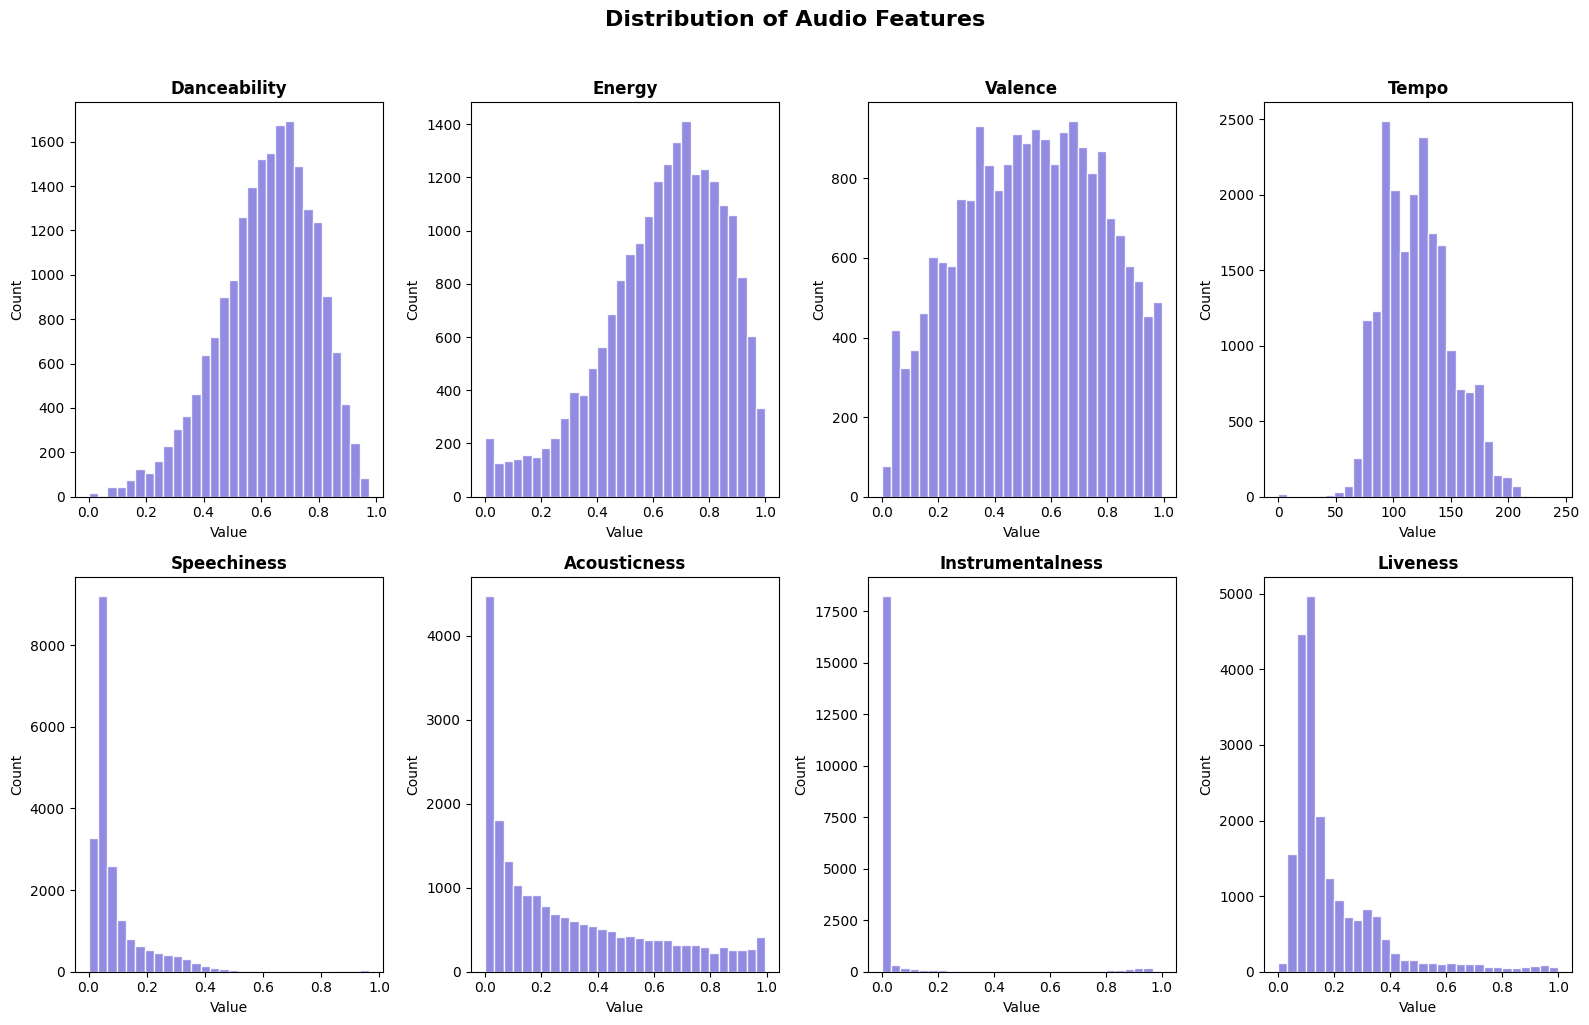

✅ Feature distributions plotted!


In [ ]:
# ============================================================
# STEP 4: EDA - Distribution of Audio Features
# ============================================================

audio_cols = ['Danceability', 'Energy', 'Valence', 'Tempo',
              'Speechiness', 'Acousticness', 'Instrumentalness', 'Liveness']

plt.figure(figsize=(16, 10))
for i, col in enumerate(audio_cols):
    plt.subplot(2, 4, i+1)
    plt.hist(df[col], bins=30, color='#7F77DD', edgecolor='white', alpha=0.85)
    plt.title(f'{col}', fontsize=12, fontweight='bold')
    plt.xlabel('Value')
    plt.ylabel('Count')

plt.suptitle('Distribution of Audio Features', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
print(" Feature distributions plotted!")

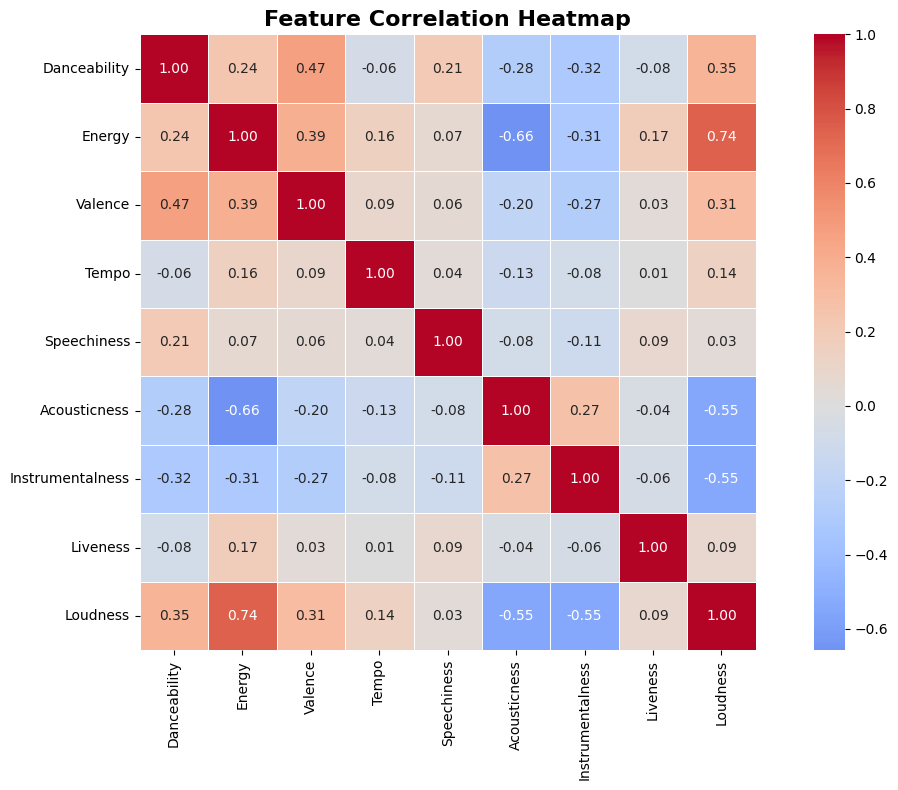


=== Top Feature Correlations ===
Energy            Loudness        0.744
Valence           Danceability    0.466
Energy            Valence         0.388
Loudness          Danceability    0.354
Valence           Loudness        0.311
Instrumentalness  Acousticness    0.274
Energy            Danceability    0.238
Speechiness       Danceability    0.210
dtype: float64


In [ ]:
# STEP 5: EDA - Correlation Heatmap

plt.figure(figsize=(12, 8))
corr_cols = ['Danceability', 'Energy', 'Valence', 'Tempo',
             'Speechiness', 'Acousticness', 'Instrumentalness',
             'Liveness', 'Loudness']

corr_matrix = df[corr_cols].corr()

sns.heatmap(corr_matrix,
            annot=True,
            fmt='.2f',
            cmap='coolwarm',
            center=0,
            square=True,
            linewidths=0.5)

plt.title('Feature Correlation Heatmap', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Print top correlations
print("\n=== Top Feature Correlations ===")
corr_pairs = corr_matrix.unstack().sort_values(ascending=False)
corr_pairs = corr_pairs[corr_pairs < 1.0].drop_duplicates()
print(corr_pairs.head(8).round(3))

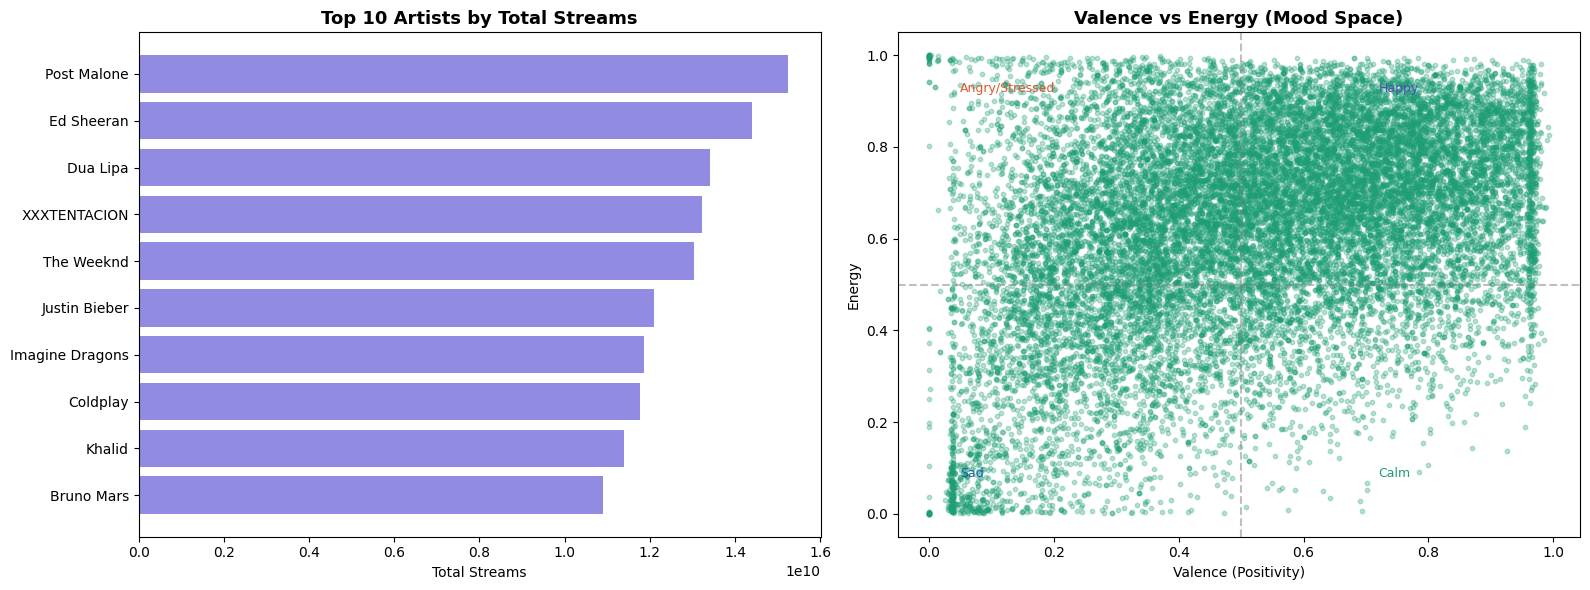

Artist & mood space plotted!


In [ ]:
# STEP 6: EDA - Top Artists & Popularity

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top 10 artists by stream count
top_artists = df.groupby('Artist')['Stream'].sum().sort_values(ascending=False).head(10)
axes[0].barh(top_artists.index[::-1], top_artists.values[::-1], color='#7F77DD', alpha=0.85)
axes[0].set_title('Top 10 Artists by Total Streams', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Total Streams')

# Valence vs Energy scatter
axes[1].scatter(df['Valence'], df['Energy'],
                alpha=0.3, color='#1D9E75', s=10)
axes[1].set_title('Valence vs Energy (Mood Space)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Valence (Positivity)')
axes[1].set_ylabel('Energy')
axes[1].axhline(0.5, color='gray', linestyle='--', alpha=0.5)
axes[1].axvline(0.5, color='gray', linestyle='--', alpha=0.5)
axes[1].text(0.05, 0.92, 'Angry/Stressed', fontsize=9, color='#D85A30')
axes[1].text(0.72, 0.92, 'Happy', fontsize=9, color='#534AB7')
axes[1].text(0.05, 0.08, 'Sad', fontsize=9, color='#185FA5')
axes[1].text(0.72, 0.08, 'Calm', fontsize=9, color='#1D9E75')

plt.tight_layout()
plt.show()
print("Artist & mood space plotted!")

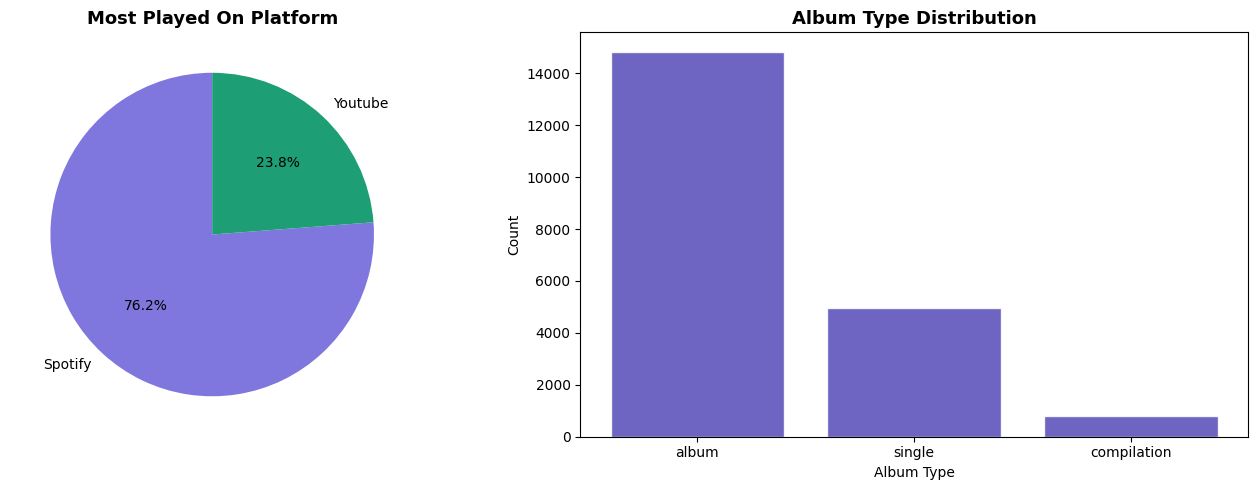

EDA complete!


In [ ]:
# ============================================================
# STEP 7: EDA - Platform & Album Analysis
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Most played on platform
if 'most_playedon' in df.columns:
    platform_counts = df['most_playedon'].value_counts()
    axes[0].pie(platform_counts.values,
                labels=platform_counts.index,
                autopct='%1.1f%%',
                colors=['#7F77DD','#1D9E75','#D85A30','#BA7517'],
                startangle=90)
    axes[0].set_title('Most Played On Platform', fontsize=13, fontweight='bold')

# Album type distribution
if 'Album_type' in df.columns:
    album_counts = df['Album_type'].value_counts()
    axes[1].bar(album_counts.index, album_counts.values,
                color='#534AB7', alpha=0.85, edgecolor='white')
    axes[1].set_title('Album Type Distribution', fontsize=13, fontweight='bold')
    axes[1].set_xlabel('Album Type')
    axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()
print("EDA complete!")

In [ ]:
# ============================================================
# STEP 8: Mood Label Creation — UPDATED (includes energetic)
# ============================================================

def assign_mood(row):
    valence = row['Valence']
    energy  = row['Energy']
    tempo   = row['Tempo']

    if valence >= 0.7 and energy >= 0.8 and tempo >= 120:
        return 'energetic'                          # ✅ new class
    elif valence >= 0.6 and energy >= 0.6:
        return 'happy'
    elif valence <= 0.35 and energy <= 0.4:
        return 'sad'
    elif energy >= 0.7 and valence <= 0.45:
        return 'stressed'
    elif valence >= 0.5 and energy <= 0.45:
        return 'calm'
    elif energy >= 0.6 and valence <= 0.55 and tempo >= 120:
        return 'overthinking'
    else:
        return 'neutral'

df['mood'] = df.apply(assign_mood, axis=1)

print("✅ Mood labels updated with ENERGETIC class!")
print("\n=== Updated Mood Distribution ===")
print(df['mood'].value_counts())

✅ Mood labels updated with ENERGETIC class!

=== Updated Mood Distribution ===
mood
neutral         7495
happy           5332
stressed        2235
sad             1744
overthinking    1591
energetic       1175
calm            1022
Name: count, dtype: int64


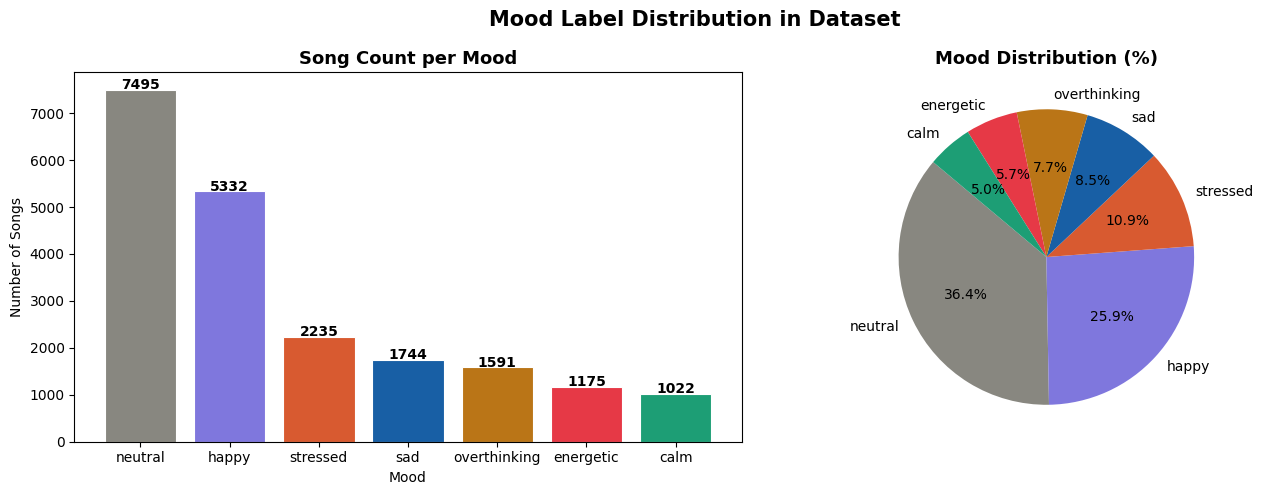

✅ Mood distribution visualized!


In [ ]:
# ============================================================
# STEP 9: Visualize Mood Distribution
# ============================================================

mood_colors = {
    'happy':       '#7F77DD',
    'sad':         '#185FA5',
    'stressed':    '#D85A30',
    'calm':        '#1D9E75',
    'overthinking':'#BA7517',
    'neutral':     '#888780',
    'energetic':   '#E63946'
}

mood_counts = df['mood'].value_counts()
colors = [mood_colors[m] for m in mood_counts.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
axes[0].bar(mood_counts.index, mood_counts.values,
            color=colors, edgecolor='white', linewidth=0.8)
axes[0].set_title('Song Count per Mood', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Mood')
axes[0].set_ylabel('Number of Songs')
for i, v in enumerate(mood_counts.values):
    axes[0].text(i, v + 10, str(v), ha='center', fontsize=10, fontweight='bold')

# Pie chart
axes[1].pie(mood_counts.values,
            labels=mood_counts.index,
            autopct='%1.1f%%',
            colors=colors,
            startangle=140)
axes[1].set_title('Mood Distribution (%)', fontsize=13, fontweight='bold')

plt.suptitle('Mood Label Distribution in Dataset', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()
print(" Mood distribution visualized!")

/tmp/ipykernel_955/122978090.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[i].boxplot(data_by_mood,
/tmp/ipykernel_955/122978090.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[i].boxplot(data_by_mood,
/tmp/ipykernel_955/122978090.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[i].boxplot(data_by_mood,
/tmp/ipykernel_955/122978090.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[i].boxplot(data_by_mood,


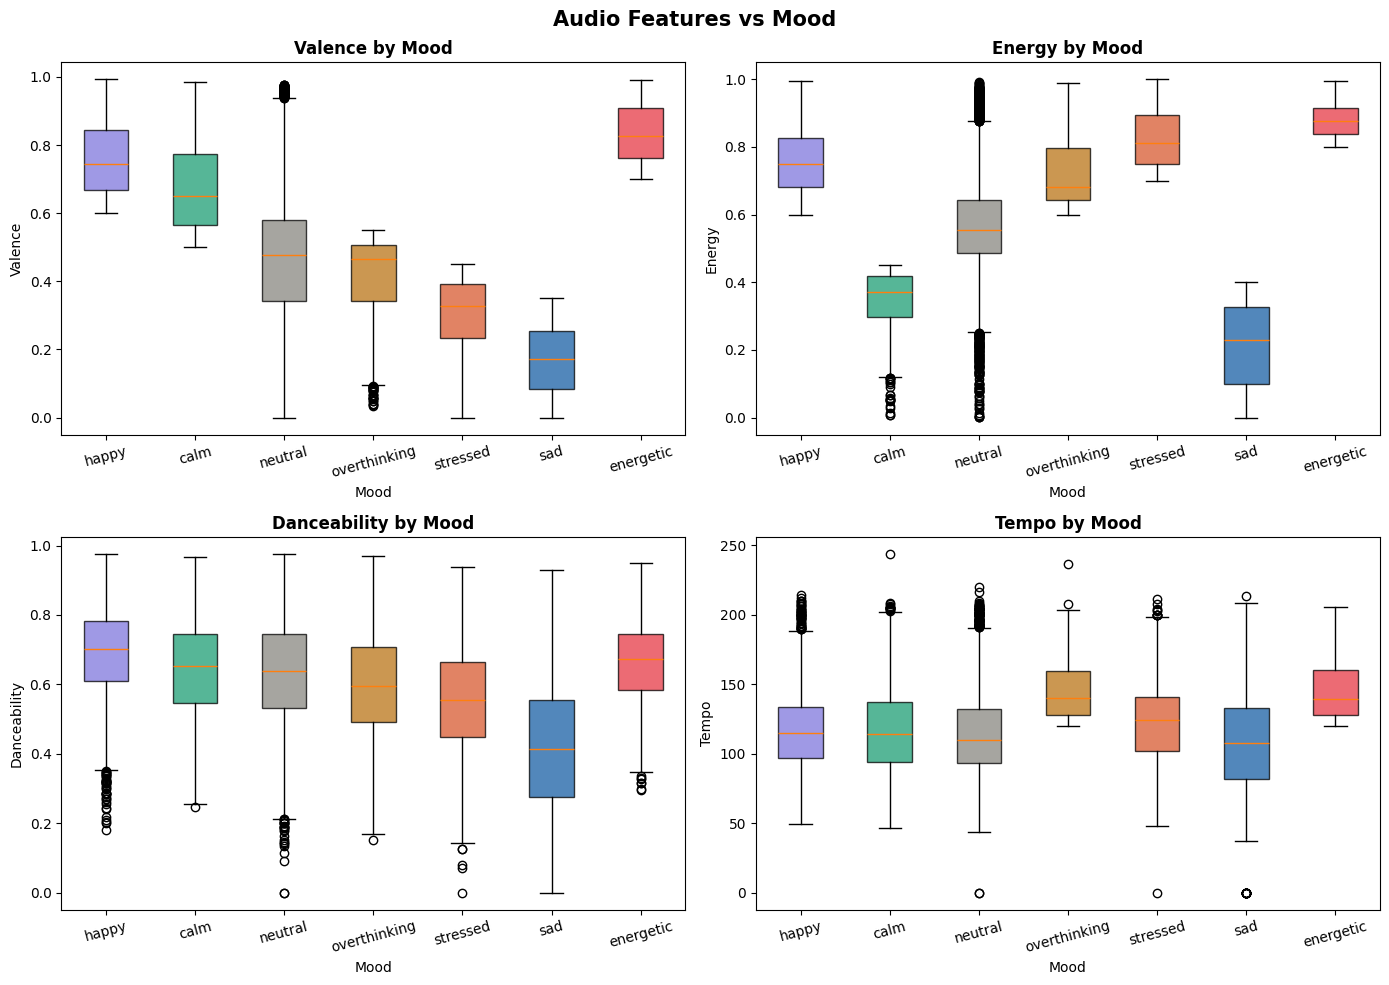

Boxplots done!


In [ ]:
# ============================================================
# STEP 10: Mood vs Audio Features (Boxplots)
# ============================================================

features_to_plot = ['Valence', 'Energy', 'Danceability', 'Tempo']
mood_order = ['happy', 'calm', 'neutral', 'overthinking', 'stressed', 'sad','energetic']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, feat in enumerate(features_to_plot):
    data_by_mood = [df[df['mood'] == m][feat].dropna().values for m in mood_order]
    bp = axes[i].boxplot(data_by_mood,
                         labels=mood_order,
                         patch_artist=True,
                         notch=False)
    colors_list = [mood_colors[m] for m in mood_order]
    for patch, color in zip(bp['boxes'], colors_list):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)
    axes[i].set_title(f'{feat} by Mood', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Mood')
    axes[i].set_ylabel(feat)
    axes[i].tick_params(axis='x', rotation=15)

plt.suptitle('Audio Features vs Mood', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()
print("Boxplots done!")

In [ ]:
# ============================================================
# STEP 11: IMPROVED — More Training Sentences
# ============================================================

mood_sentences = {
    'sad': [
        "i am feeling sad today",
        "i feel so lonely and empty",
        "i am heartbroken and crying",
        "everything feels hopeless",
        "i miss someone so much",
        "i feel depressed and down",
        "nothing makes me happy",
        "i feel like crying all day",
        "i am grieving and lost",
        "life feels meaningless right now",
        "i feel broken inside",
        "tears won't stop falling",
        "i feel so blue today",
        "my heart is heavy with sadness",
        "i feel unloved and unwanted",
        "i am so unhappy right now",
        "feeling down and hopeless",
        "i cant stop crying",
        "i feel numb and empty inside",
        "nobody understands my pain",
    ],
    'stressed': [
        "i am so stressed out",
        "i have too much work and pressure",
        "deadlines are killing me",
        "i feel so overwhelmed",
        "i am anxious about everything",
        "i feel nervous and tense",
        "my heart is racing with anxiety",
        "i cant handle this pressure",
        "everything is piling up on me",
        "i feel burned out completely",
        "i am panicking about my work",
        "too much stress in my life",
        "i feel like i am drowning in work",
        "i cannot breathe with all this pressure",
        "i am exhausted from all the stress",
        "my mind is overwhelmed with tasks",
        "i feel so much pressure from everyone",
        "i am struggling to cope with stress",
        "everything feels urgent and rushed",
        "i have no time and too much to do",
    ],
    'overthinking': [
        "i cannot stop thinking",
        "my mind is running in circles",
        "i keep overthinking everything",
        "what if things go wrong",
        "i am stuck in my head",
        "thoughts won't let me sleep",
        "i keep replaying things in my mind",
        "i am spiraling with thoughts",
        "my brain won't shut off",
        "i am lost in my own thoughts",
        "i keep worrying about what if",
        "i cannot stop ruminating",
        "my thoughts are going in loops",
        "i analyze everything too much",
        "i cant stop second guessing myself",
        "my mind never stops thinking",
        "i overthink every little decision",
        "i am trapped inside my own head",
        "i keep thinking about what could go wrong",
        "my thoughts are driving me crazy",
    ],
    'happy': [
        "i am feeling so happy today",
        "life is amazing and wonderful",
        "i feel so joyful and excited",
        "everything is going great",
        "i am in a fantastic mood",
        "feeling blessed and grateful",
        "today is a wonderful day",
        "i feel elated and cheerful",
        "i am so excited right now",
        "good vibes only today",
        "i feel on top of the world",
        "feeling great and energetic",
        "i am so thrilled about everything",
        "life could not be better right now",
        "i feel so positive and upbeat",
        "everything makes me smile today",
        "i am bursting with happiness",
        "feeling so alive and joyful",
        "i am in the best mood ever",
        "today is absolutely perfect",
    ],
    'calm': [
        "i feel calm and peaceful",
        "i want to relax and unwind",
        "i am in a quiet and serene mood",
        "i feel settled and at ease",
        "i just want some peace",
        "feeling chill and relaxed today",
        "i am in a gentle and soft mood",
        "everything feels okay and fine",
        "i want to sit back and breathe",
        "i feel centered and grounded",
        "i am feeling mellow today",
        "just a quiet peaceful day",
        "i feel tranquil and undisturbed",
        "my mind is at peace today",
        "i feel so relaxed and comfortable",
        "everything is slow and gentle today",
        "i am feeling very zen right now",
        "i feel no stress or worry",
        "i am completely at ease today",
        "feeling soft and quiet inside",
    ],
    'neutral': [
        "i feel okay today",
        "nothing special just a normal day",
        "i am doing alright",
        "feeling average and normal",
        "just a regular day for me",
        "i am fine nothing much",
        "today is just a normal day",
        "feeling meh not good not bad",
        "i am neither happy nor sad",
        "just going through the day",
        "feeling usual and ordinary",
        "nothing exciting happening today",
        "i am just existing today",
        "today is pretty uneventful",
        "i feel indifferent about everything",
        "nothing is wrong but nothing is great",
        "i am just going through the motions",
        "feeling blank and expressionless",
        "today is just another day",
        "i have no strong feelings right now",
    ],
    'energetic': [
        "i feel so pumped and energetic",
        "i am ready to take on the world",
        "i feel so alive and powerful",
        "i have so much energy right now",
        "i feel unstoppable today",
        "i am fired up and motivated",
        "i feel like running and jumping",
        "everything feels electric today",
        "i am bursting with energy",
        "i feel so hyped and active",
        "i want to dance and move",
        "i am full of power and drive",
        "i feel so dynamic and strong",
        "i am ready to crush my goals",
        "feeling super charged today",
        "i have an incredible energy boost",
        "i feel like i can do anything",
        "i am so motivated and driven",
        "feeling wild and free today",
        "i am on fire right now",
    ]
}

texts = []
labels = []
for mood, sentences in mood_sentences.items():
    for sentence in sentences:
        texts.append(sentence)
        labels.append(mood)

text_df = pd.DataFrame({'text': texts, 'mood': labels})

print(" Improved training data created!")
print(f"Total training sentences: {len(text_df)}")
print("\n=== Samples per mood ===")
print(text_df['mood'].value_counts())

✅ Improved training data created!
Total training sentences: 140

=== Samples per mood ===
mood
sad             20
stressed        20
overthinking    20
happy           20
calm            20
neutral         20
energetic       20
Name: count, dtype: int64


In [ ]:
# ============================================================
# STEP 12: Train Naive Bayes Classifier
# ============================================================

# Step 1: Convert text to numbers using CountVectorizer (Bag of Words)
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(text_df['text'])
y = text_df['mood']

# Step 2: Encode labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Step 3: Train/Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Step 4: Train Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

# Step 5: Evaluate
y_pred = nb_model.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print("Naive Bayes Model Trained!")
print(f"\n=== Model Accuracy: {acc*100:.2f}% ===")
print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred,
      target_names=le.classes_))

✅ Naive Bayes Model Trained!

=== Model Accuracy: 28.57% ===

=== Classification Report ===
              precision    recall  f1-score   support

        calm       0.50      0.25      0.33         4
   energetic       0.25      0.25      0.25         4
       happy       0.33      0.50      0.40         4
     neutral       0.29      0.50      0.36         4
overthinking       0.67      0.50      0.57         4
         sad       0.00      0.00      0.00         4
    stressed       0.00      0.00      0.00         4

    accuracy                           0.29        28
   macro avg       0.29      0.29      0.27        28
weighted avg       0.29      0.29      0.27        28



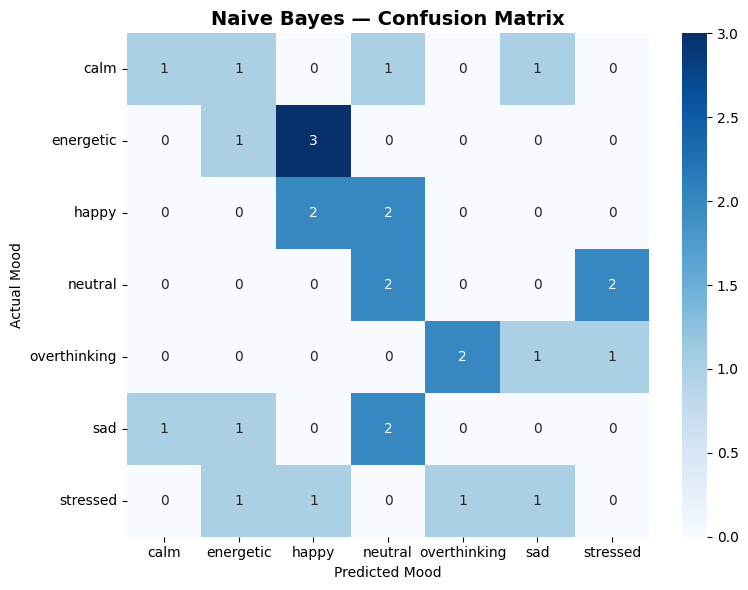

Confusion matrix plotted!


In [ ]:
# ============================================================
# STEP 13: Naive Bayes - Confusion Matrix
# ============================================================

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=le.classes_,
            yticklabels=le.classes_)

plt.title('Naive Bayes — Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Mood')
plt.ylabel('Actual Mood')
plt.tight_layout()
plt.show()
print("Confusion matrix plotted!")

In [ ]:
# ============================================================
# STEP 15: Mood Transformation Engine (Rule-Based) — UPDATED
# ============================================================

MOOD_TRANSFORM = {
    'sad':         {'path': ['sad', 'calm', 'happy'],           'target': 'happy'},
    'stressed':    {'path': ['stressed', 'calm', 'happy'],      'target': 'calm'},
    'overthinking':{'path': ['overthinking', 'calm', 'happy'],  'target': 'calm'},
    'neutral':     {'path': ['neutral', 'happy', 'energetic'],  'target': 'happy'},
    'calm':        {'path': ['calm', 'happy', 'energetic'],     'target': 'happy'},
    'happy':       {'path': ['happy', 'energetic'],             'target': 'energetic'},  #  your idea!
}

def transform_mood(detected_mood):
    info = MOOD_TRANSFORM[detected_mood]
    path = info['path']
    target = info['target']

    print(f"\n🔄 Mood Transformation Path:")
    print(f"   {' → '.join(path)}")
    print(f"🎯 We will recommend songs to move you towards: {target.upper()}")

    return target

# Test it
print("=== Mood Transformation Examples ===")
for mood in MOOD_TRANSFORM:
    path = MOOD_TRANSFORM[mood]['path']
    print(f"  {mood:<14} → {' → '.join(path)}")

=== Mood Transformation Examples ===
  sad            → sad → calm → happy
  stressed       → stressed → calm → happy
  overthinking   → overthinking → calm → happy
  neutral        → neutral → happy → energetic
  calm           → calm → happy → energetic
  happy          → happy → energetic


In [ ]:
# ============================================================
# STEP 16: Prepare Feature Matrix for KNN
# ============================================================

# Features used for similarity
feature_cols = ['Danceability', 'Energy', 'Valence',
                'Tempo', 'Acousticness', 'Liveness']

# Drop rows with nulls in feature cols
df_model = df.dropna(subset=feature_cols + ['mood']).copy()

# Normalize features to 0-1 range
scaler = MinMaxScaler()
df_model[feature_cols] = scaler.fit_transform(df_model[feature_cols])

# Encode mood labels
le_mood = LabelEncoder()
df_model['mood_encoded'] = le_mood.fit_transform(df_model['mood'])

print(" Feature matrix ready!")
print(f"Songs available for recommendation: {len(df_model)}")
print(f"Mood classes: {list(le_mood.classes_)}")
print(f"\nFeature preview:")
display(df_model[['Track', 'Artist', 'mood'] + feature_cols].head())

 Feature matrix ready!
Songs available for recommendation: 20594
Mood classes: ['calm', 'energetic', 'happy', 'neutral', 'overthinking', 'sad', 'stressed']

Feature preview:


,Track,Artist,mood,Danceability,Energy,Valence,Tempo,Acousticness,Liveness
0,Feel Good Inc.,Gorillaz,happy,0.838974,0.705,0.777442,0.569330,0.008394,0.6130
1,Rhinestone Eyes,Gorillaz,happy,0.693333,0.703,0.858006,0.381149,0.087249,0.0463
2,New Gold (feat. Tame Impala and Bootie Brown),Gorillaz,neutral,0.712821,0.923,0.554884,0.443823,0.042671,0.1160
3,On Melancholy Hill,Gorillaz,neutral,0.706667,0.739,0.582075,0.494810,0.000015,0.0640
4,Clint Eastwood,Gorillaz,overthinking,0.680000,0.694,0.528701,0.690108,0.025402,0.0698


In [ ]:
# ============================================================
# STEP 17: Train KNN Model
# ============================================================

X_songs = df_model[feature_cols].values
y_songs = df_model['mood_encoded'].values

# Train/test split
X_tr, X_te, y_tr, y_te = train_test_split(
    X_songs, y_songs, test_size=0.2, random_state=42
)

# KNN with k=5
knn_model = KNeighborsClassifier(n_neighbors=5, metric='cosine')
knn_model.fit(X_tr, y_tr)

knn_acc = accuracy_score(y_te, knn_model.predict(X_te))

print(" KNN Model Trained!")
print(f"K = 5, Metric = Cosine Similarity")
print(f"Accuracy: {knn_acc*100:.2f}%")
print("\n=== KNN Classification Report ===")
print(classification_report(y_te, knn_model.predict(X_te),
      target_names=le_mood.classes_))

 KNN Model Trained!
K = 5, Metric = Cosine Similarity
Accuracy: 73.15%

=== KNN Classification Report ===
              precision    recall  f1-score   support

        calm       0.81      0.62      0.70       202
   energetic       0.66      0.62      0.64       239
       happy       0.75      0.84      0.79      1065
     neutral       0.71      0.72      0.71      1512
overthinking       0.55      0.51      0.53       318
         sad       0.88      0.80      0.84       341
    stressed       0.78      0.75      0.77       442

    accuracy                           0.73      4119
   macro avg       0.74      0.69      0.71      4119
weighted avg       0.73      0.73      0.73      4119



In [ ]:
# ============================================================
# STEP 19: Decision Tree — Song Mood Classifier
# ============================================================

X_songs = df_model[feature_cols].values
y_songs = df_model['mood_encoded'].values

X_tr, X_te, y_tr, y_te = train_test_split(
    X_songs, y_songs, test_size=0.2, random_state=42
)

# Train Decision Tree
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_tr, y_tr)

dt_acc = accuracy_score(y_te, dt_model.predict(X_te))
print("Decision Tree Trained!")
print(f"Accuracy: {dt_acc*100:.2f}%")
print("\n=== Classification Report ===")
print(classification_report(y_te, dt_model.predict(X_te),
      target_names=le_mood.classes_))

Decision Tree Trained!
Accuracy: 96.92%

=== Classification Report ===
              precision    recall  f1-score   support

        calm       1.00      0.85      0.92       202
   energetic       1.00      1.00      1.00       239
       happy       1.00      1.00      1.00      1065
     neutral       0.98      0.94      0.96      1512
overthinking       0.78      0.99      0.87       318
         sad       1.00      1.00      1.00       341
    stressed       1.00      1.00      1.00       442

    accuracy                           0.97      4119
   macro avg       0.96      0.97      0.96      4119
weighted avg       0.97      0.97      0.97      4119



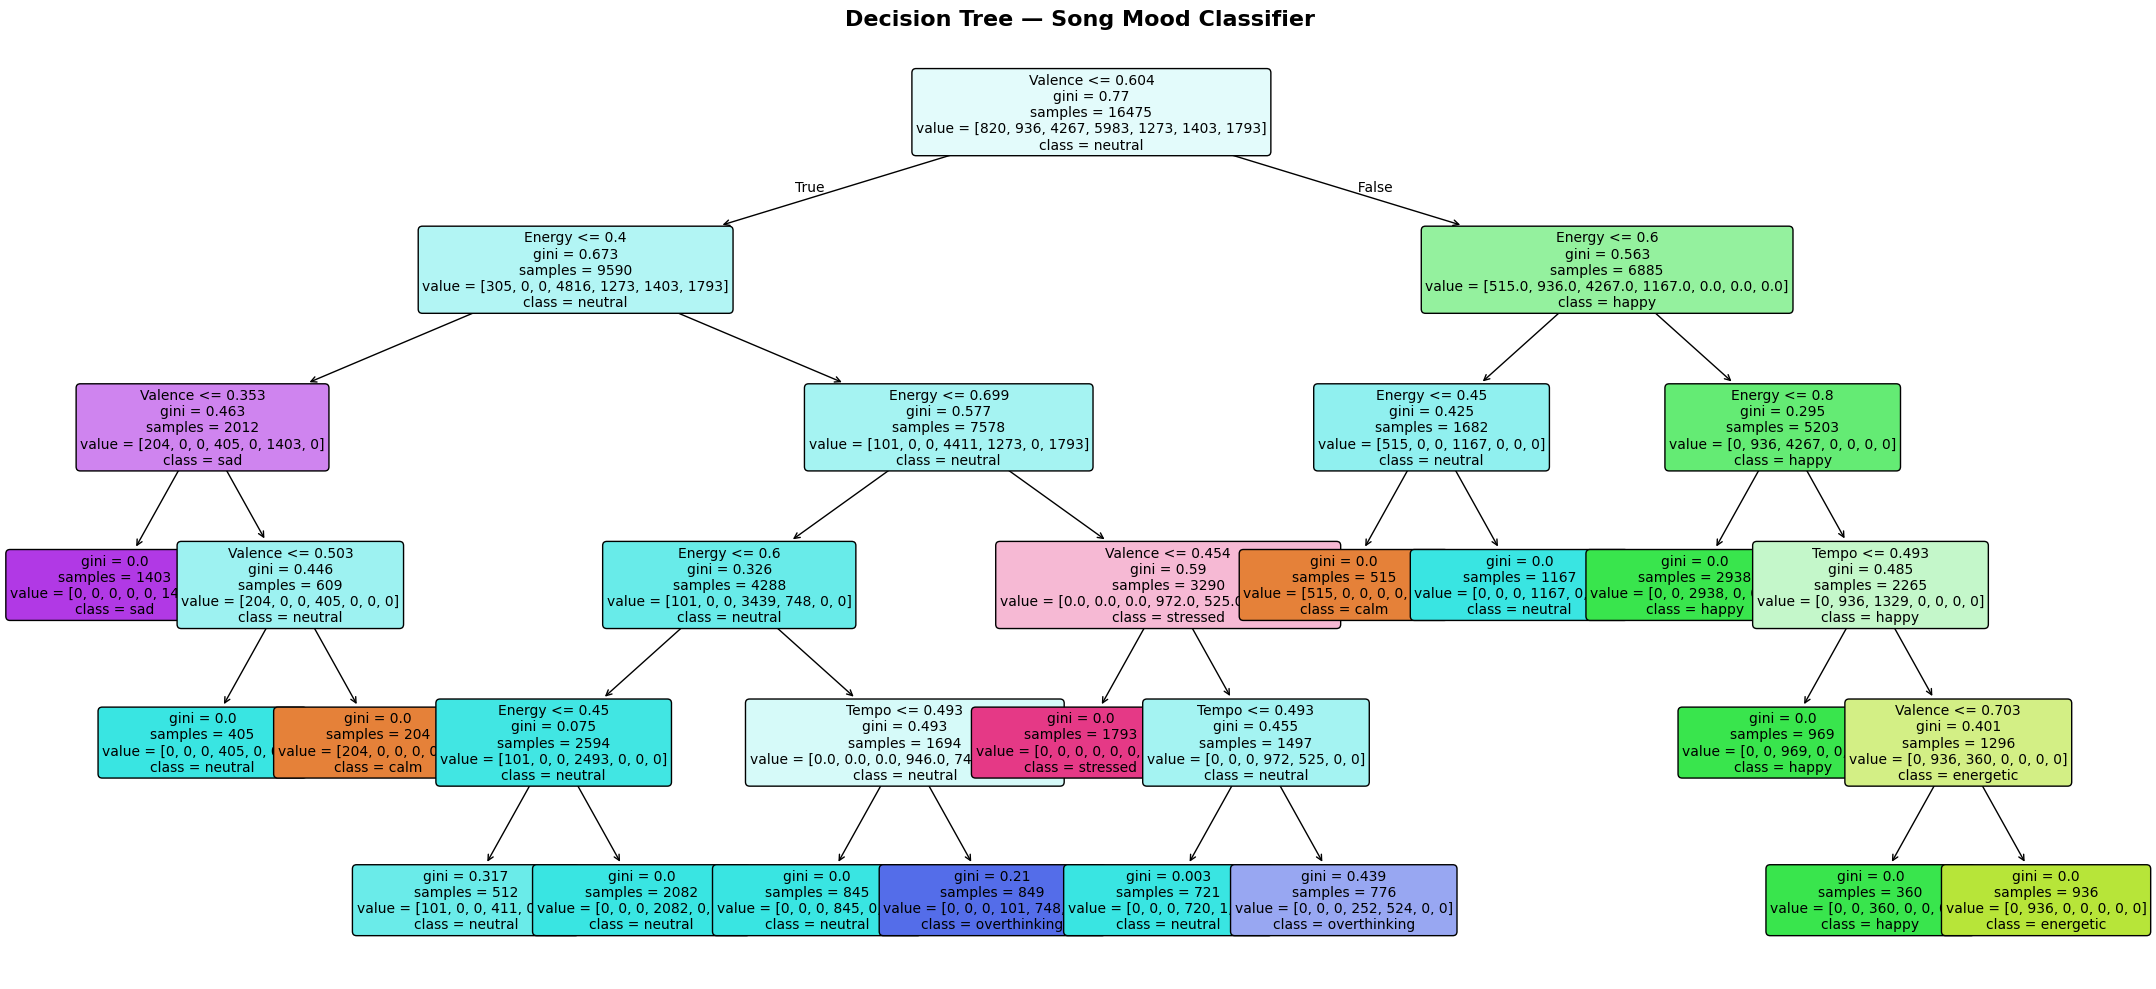

Decision Tree visualized!


In [ ]:
# ============================================================
# STEP 20: Visualize Decision Tree
# ============================================================

plt.figure(figsize=(22, 10))
plot_tree(dt_model,
          feature_names=feature_cols,
          class_names=le_mood.classes_,
          filled=True,
          rounded=True,
          fontsize=10)
plt.title('Decision Tree — Song Mood Classifier', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()
print("Decision Tree visualized!")

In [ ]:
# ============================================================
# STEP 21: FULL PIPELINE — Mood Music Recommendation System
# ============================================================

from sklearn.metrics.pairwise import cosine_similarity

def full_pipeline(user_text):
    print("\n" + "="*65)
    print("         MOOD MUSIC RECOMMENDATION SYSTEM   ")
    print("="*65)

    # ── STAGE 1: Naive Bayes Mood Detection ──────────────────
    print(f"\n Your Input: '{user_text}'")
    print("\n── STAGE 1: Naive Bayes Mood Detection ──")

    text_vectorized = vectorizer.transform([user_text])
    detected_encoded = nb_model.predict(text_vectorized)[0]
    detected_mood = le.inverse_transform([detected_encoded])[0]

    probs = nb_model.predict_proba(text_vectorized)[0]
    mood_probs = dict(zip(le.classes_, probs))
    mood_probs_sorted = dict(sorted(mood_probs.items(),
                             key=lambda x: x[1], reverse=True))

    print(f" Detected Mood: {detected_mood.upper()}")
    print("\n Mood Probabilities:")
    for mood, prob in mood_probs_sorted.items():
        bar = '█' * int(prob * 25)
        print(f"   {mood:<14} {bar:<25} {prob*100:.1f}%")

    # ── STAGE 2: Mood Transformation ─────────────────────────
    print("\n── STAGE 2: Mood Transformation Engine ──")
    if detected_mood in MOOD_TRANSFORM:
        info = MOOD_TRANSFORM[detected_mood]
        path = info['path']
        target_mood = info['target']
        print(f"Path : {' → '.join(path)}")
        print(f" Target: {target_mood.upper()}")
    else:
        target_mood = 'happy'
        print(f" Default target: HAPPY")

    # ── STAGE 3: KNN + Cosine Similarity Recommendation ──────
    print(f"\n── STAGE 3: KNN Recommendation (target = {target_mood}) ──")

    mood_songs = df_model[df_model['mood'] == target_mood].copy()

    if len(mood_songs) == 0:
        print(f"No songs found for {target_mood}, switching to happy")
        mood_songs = df_model[df_model['mood'] == 'happy'].copy()

    target_vector = mood_songs[feature_cols].mean().values.reshape(1, -1)
    all_vectors   = mood_songs[feature_cols].values
    similarities  = cosine_similarity(target_vector, all_vectors)[0]
    mood_songs    = mood_songs.copy()
    mood_songs['similarity'] = similarities

    if 'Stream' in mood_songs.columns:
        max_stream = mood_songs['Stream'].max()
        mood_songs['pop_score']   = mood_songs['Stream'] / max_stream
        mood_songs['final_score'] = (0.6 * mood_songs['similarity'] +
                                     0.4 * mood_songs['pop_score'])
    else:
        mood_songs['final_score'] = mood_songs['similarity']

    top5 = mood_songs.sort_values('final_score', ascending=False).head(5)

    print(f"\n Top 5 Songs to move you → {target_mood.upper()}")
    print("="*65)
    for i, (_, row) in enumerate(top5.iterrows(), 1):
        print(f"{i}.  {row['Track']}")
        print(f"   Artist     : {row['Artist']}")
        print(f"   Energy     : {row['Energy']:.2f}  |  "
              f"Valence : {row['Valence']:.2f}  |  "
              f"Dance   : {row['Danceability']:.2f}")
        print(f"   Score      : {row['final_score']:.3f}")
        print("-"*65)

    # ── STAGE 4: Decision Tree Mood Tag ──────────────────────
    print("\n── STAGE 4: Decision Tree — Song Mood Verification ──")
    for i, (_, row) in enumerate(top5.iterrows(), 1):
        feat_vec = scaler.transform([row[feature_cols].values])
        dt_pred  = dt_model.predict(feat_vec)[0]
        dt_mood  = le_mood.inverse_transform([dt_pred])[0]
        print(f"   {i}. {row['Track'][:35]:<35} → DT says: {dt_mood}")

    print("\n" + "="*65)
    print(" Pipeline complete! Enjoy your music ")
    print("="*65)

# ── RUN THE SYSTEM ────────────────────────────────────────────
user_input = input("\n How are you feeling right now? → ")
full_pipeline(user_input)


 How are you feeling right now? → clam

         MOOD MUSIC RECOMMENDATION SYSTEM   

 Your Input: 'clam'

── STAGE 1: Naive Bayes Mood Detection ──
 Detected Mood: CALM

 Mood Probabilities:
   calm           ███                       14.3%
   energetic      ███                       14.3%
   happy          ███                       14.3%
   neutral        ███                       14.3%
   overthinking   ███                       14.3%
   sad            ███                       14.3%
   stressed       ███                       14.3%

── STAGE 2: Mood Transformation Engine ──
Path : calm → happy → energetic
 Target: HAPPY

── STAGE 3: KNN Recommendation (target = happy) ──

 Top 5 Songs to move you → HAPPY
1.  Shape of You
   Artist     : Ed Sheeran
   Energy     : 0.65  |  Valence : 0.94  |  Dance   : 0.85
   Score      : 0.975
-----------------------------------------------------------------
2.  Believer
   Artist     : Imagine Dragons
   Energy     : 0.78  |  Valence : 0.67  |  D

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


In [ ]:
# ============================================================
# Model Accuracy Summary
# ============================================================

print("=" * 45)
print("       MODEL ACCURACY SUMMARY")
print("=" * 45)
print(f"  Naive Bayes  (Mood Detection) : {acc*100:.2f}%")
print(f"  KNN k=5      (Song Mood)      : {knn_acc*100:.2f}%")
print(f"  Decision Tree(Song Mood)      : {dt_acc*100:.2f}%")
print("=" * 45)

       MODEL ACCURACY SUMMARY
  Naive Bayes  (Mood Detection) : 28.57%
  KNN k=5      (Song Mood)      : 73.15%
  Decision Tree(Song Mood)      : 96.92%
